In [2]:
import numpy as np                          # cuentas con vectores y matrices
from scipy.integrate import solve_ivp      # resuelve ecuaciones diferenciales
import matplotlib.pyplot as plt
import random

#################################################################
############  simular

def condiciones_iniciales_random(n, semilla=None):
    # Devuelve n fases al azar, uniformes entre 0 y 2*pi.
    rng = np.random.default_rng(semilla)    # generador de números aleatorios
    return rng.uniform(-np.pi, np.pi, n)


def potencial(phi, A, K, Delta):
    # V = sum_i (1/d) sum_{j vecino de i} (1/2) K_ji (1 - cos(phi_j - phi_i - Delta_ji))
    n = len(phi)                            # cantidad de nodos
    d = 4                          # grado (es el mismo para todos)
    V = 0.0                                 # acumulador
    for i in range(n):                      # para cada nodo i
        for j in range(n):                  # mira todos los j
            if A[i, j] == 1:                # pero solo suma si j es vecino de i
                V += (1 / d) * 0.5 * K[j, i] * (1 - np.cos(phi[j] - phi[i] - Delta[j, i]))
    return V


def ecuaciones(t, phi, A, K, Delta, omega=0.0):
    # dphi_i/dt = omega - dV/dphi_i
    #           = omega + (1/d) sum_{j vecino de i} [ (K_ji/2) sin(phi_j - phi_i - Delta_ji)
    #                                                + (K_ij/2) sin(phi_j - phi_i + Delta_ij) ]
    # (t no se usa, pero solve_ivp lo pide como primer argumento)
    n = len(phi)                            # cantidad de nodos
    d = A[0].sum()                          # grado
    dphi = np.full(n, omega)                # empieza con la frecuencia natural
    for i in range(n):                      # para cada nodo i
        for j in range(n):                  # mira todos los j
            if A[i, j] == 1:                # solo los vecinos aportan
                dphi[i] += (1 / d) * 0.5 * K[j, i] * np.sin(phi[j] - phi[i] - Delta[j, i])
                dphi[i] += (1 / d) * 0.5 * K[i, j] * np.sin(phi[j] - phi[i] + Delta[i, j])
    return dphi


def simular(phi0, A, K, Delta, T, omega=0.0):
    # Integra las ecuaciones desde t=0 hasta t=T partiendo de phi0.
    sol = solve_ivp(ecuaciones, (0, T), phi0, args=(A, K, Delta, omega),
                    rtol=1e-8, atol=1e-10)  # tolerancias chicas = más precisión
    return sol.t, sol.y                     # tiempos y fases (sol.y[i] es la fase del nodo i)

############################################################################################
################# matrices importantes

def matriz_ady(n):
      A = np.full((n,n), 0)
      for i in range(n-1):
        A[i,i+1] = 1
        A[i+1,i] = 1
      return A

def matriz_flow_uni(n):
      K = np.full((n,n), 0)
      for i in range(n-1):
        K[i,i+1] = 1
      return K

def matriz_flow_bi(n):
      K = np.full((n,n), 0)
      for i in range(n-1):
        K[i,i+1] = 1
        K[i+1,i] = 1
      return K

def matriz_K1(n, av, perp, primera_sube=True):
  # n = cruces por calle (columnas); filas: 0 = calle de arriba, 1 = doble mano, 2 = calle de abajo
  m = 3 * n
  K = np.zeros((m, m))                           # float: si no, perp = 0.8 se trunca a 0

  for i in range(n - 1):
    K[i, i + 1] = av                             # arriba: solo hacia la derecha (i -> i+1)
    K[n + i, n + i + 1] = av                     # medio: doble mano, hacia la derecha...
    K[n + i + 1, n + i] = av                     # ...y hacia la izquierda
    K[2*n + i + 1, 2*n + i] = av                 # abajo: solo hacia la izquierda (i+1 -> i)

  for i in range(n):                             # perpendiculares: sentidos alternados
    sube = (i % 2 == 0) == primera_sube          # con primera_sube=True, la columna 0 sube
    if sube:
      K[2*n + i, n + i] = perp                   # fila de abajo -> fila del medio
      K[n + i, i] = perp                         # fila del medio -> fila de arriba
    else:
      K[i, n + i] = perp                         # fila de arriba -> fila del medio
      K[n + i, 2*n + i] = perp                   # fila del medio -> fila de abajo
  return K

def matriz_ady1(n, calles=3):
  # n = cruces por calle (columnas), calles = calles paralelas (filas)
  m = calles * n                        # cantidad total de semáforos
  A = np.zeros((m, m), dtype=int)

  for c in range(calles):               # cada calle paralela
    for i in range(n):                  # cada cruce de esa calle
      k = c * n + i                     # índice del semáforo (calle c, cruce i)
      if i + 1 < n:                     # vecino siguiente sobre la misma calle
        A[k, k + 1] = 1
        A[k + 1, k] = 1
      if c + 1 < calles:                # vecino de la calle de abajo (perpendicular)
        A[k, k + n] = 1
        A[k + n, k] = 1
  return A


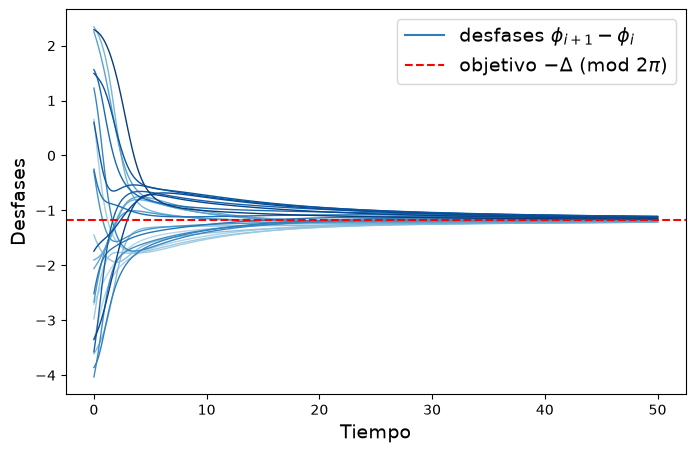

fases iniciales: [ 2.78380361  0.07117311  2.99232745 -2.63368494  0.67453659 -0.77605768
  1.89690123 -2.04500204  2.33505329  0.27609196  2.52719188 -0.14354864
 -0.43670477  1.81550577  3.04202302 -0.81853699  2.94639211  2.6956523
 -2.02511721  0.68393488  1.28720316  2.78221757  1.04085625 -2.3034424
 -0.01339827]
Potencial inicial: 3.7248109871175132
Potencial final:   0.0024209444581521633
Delta = 0π/8 | V inicial = 1.298 | V final = 0.000
Delta = 1π/8 | V inicial = 0.774 | V final = 0.076
Delta = 2π/8 | V inicial = 1.159 | V final = 0.293
Delta = 3π/8 | V inicial = 1.086 | V final = 0.617
Delta = 5π/8 | V inicial = 0.891 | V final = 0.617
Delta = 6π/8 | V inicial = 0.678 | V final = 0.293
Delta = 7π/8 | V inicial = 0.579 | V final = 0.076
Delta = 8π/8 | V inicial = 0.702 | V final = 0.000


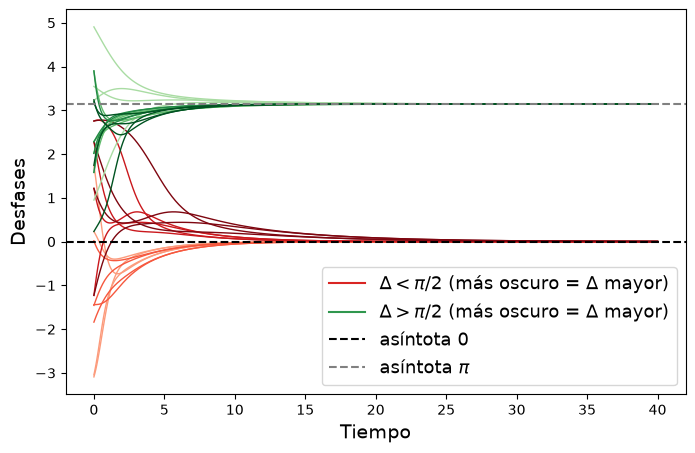

In [3]:
def normalizar(d, centro=0.0):
    # corre la curva d un múltiplo de 2*pi para que su valor final quede lo más cerca posible de `centro`
    return d - 2*np.pi*np.round((d[-1] - centro) / (2*np.pi))


# ------------------------------- Calle recta, un solo sentido -------------------------------

n = 25
T = 50

A = matriz_ady(n)
K = matriz_flow_uni(n)
Delta = np.full((n, n), 3 * np.pi / 8)                      # todos los desfases iguales

phi0 = condiciones_iniciales_random(n, semilla=random.randint(1, 10))   # fases iniciales al azar
t, phi = simular(phi0, A, K, Delta, T)
phi_final = phi[:, -1]

objetivo = -Delta[0, 0]                                     # en un sentido: phi_{i+1} - phi_i = -Delta
tonos = np.linspace(0.3, 0.95, n - 1)                       # claro -> oscuro en el sentido de circulación

plt.figure(figsize=(8, 5))
for i, tono in enumerate(tonos):
    plt.plot(t, normalizar(phi[i+1] - phi[i], objetivo), color=plt.cm.Blues(tono), lw=1)
plt.plot([], [], color=plt.cm.Blues(0.7), label=r'desfases $\phi_{i+1}-\phi_i$')
plt.axhline(objetivo, linestyle='--', color='red', label=r'objetivo $-\Delta$ (mod $2\pi$)')
plt.legend(fontsize = 14)
plt.xlabel('Tiempo', fontsize = 14)
plt.ylabel('Desfases', fontsize = 14)
plt.show()

print('fases iniciales:', phi0)
print('Potencial inicial:', potencial(phi0, A, K, Delta))
print('Potencial final:  ', potencial(phi_final, A, K, Delta))


# ------------------------------- Calle recta, ambos sentidos -------------------------------

n = 5
T = 40

A = matriz_ady(n)
K = matriz_flow_bi(n)

# (nombre, colores, valor al que convergen, múltiplos de pi/8 para Delta)
grupos = [(r'$\Delta<\pi/2$', plt.cm.Reds,   0.0,   [0, 1, 2, 3]),
          (r'$\Delta>\pi/2$', plt.cm.Greens, np.pi, [5, 6, 7, 8])]

plt.figure(figsize=(8, 5))
for nombre, cmap, centro, multiplos in grupos:
    tonos = np.linspace(0.35, 0.95, len(multiplos))         # más oscuro = Delta más grande
    for j, tono in zip(multiplos, tonos):
        Delta = np.full((n, n), j * np.pi / 8)
        phi0 = condiciones_iniciales_random(n, semilla=random.randint(1, 10))
        t, phi = simular(phi0, A, K, Delta, T)
        for i in range(n - 1):
            plt.plot(t, normalizar(phi[i+1] - phi[i], centro), color=cmap(tono), lw=1)
        print(f'Delta = {j}π/8 | V inicial = {potencial(phi0, A, K, Delta):.3f} | V final = {potencial(phi[:, -1], A, K, Delta):.3f}')
    plt.plot([], [], color=cmap(0.7), label=nombre + ' (más oscuro = Δ mayor)')

plt.axhline(0,     linestyle='--', color='black', label='asíntota 0')
plt.axhline(np.pi, linestyle='--', color='gray',  label=r'asíntota $\pi$')
plt.legend(fontsize = 13)
plt.xlabel('Tiempo', fontsize = 14)
plt.ylabel('Desfases', fontsize = 14)
plt.show()

In [4]:
import numpy as np
from scipy.integrate import solve_ivp

# --- avenida + perpendiculares + paralelas---

# --- Parámetros fijos ---
m_zero = 10
n_zero = 3 * m_zero
N_CI_zero = 50
T_MAX_zero = 300
K_AV_zero = 10.0

# --- Matrices básicas aisladas ---
A_zero = matriz_ady1(m_zero)
Delta_zero = np.full((n_zero, n_zero), 2 * np.pi / 8)
# Fuerza bruta: K_perp = 0
K_zero = matriz_K1(m_zero, K_AV_zero, 0.0)

lista_V0 = []
lista_Vfin = []
fallos = 0

# --- Funciones matemáticas aisladas ---
def V_aislado(phi):
    D = phi[None, :] - phi[:, None]
    d = A_zero[0].sum()
    return (A_zero * 0.5 * K_zero.T * (1 - np.cos(D - Delta_zero.T))).sum() / d

def rhs_aislado(t, phi):
    D = phi[None, :] - phi[:, None]
    d = A_zero[0].sum()
    return (A_zero * (0.5 * K_zero.T * np.sin(D - Delta_zero.T) +
                      0.5 * K_zero * np.sin(D + Delta_zero))).sum(axis=1) / d

def convergio_aislado(t, phi):
    return np.abs(rhs_aislado(t, phi)).max() - 1e-6
convergio_aislado.terminal = True

print("Iniciando corrida para K=0...")

# --- Simulación ---
for b in range(N_CI_zero):
    phi0 = condiciones_iniciales_random(n_zero, semilla=b)

    # Potencial inicial
    lista_V0.append(V_aislado(phi0))

    # Ecuación diferencial
    sol = solve_ivp(rhs_aislado, (0, T_MAX_zero), phi0,
                    events=convergio_aislado, rtol=1e-8, atol=1e-10)

    # Potencial final
    phi_f = sol.y[:, -1]
    lista_Vfin.append(V_aislado(phi_f))

    fallos += (sol.status != 1)

print(f"Fallos de convergencia: {fallos}")
print("\n--- Copia esto ---")
print(f"V0_K0 = {lista_V0}")
print(f"Vfin_K0 = {lista_Vfin}")

Iniciando corrida para K=0...
Fallos de convergencia: 0

--- Copia esto ---
V0_K0 = [np.float64(82.12951839745185), np.float64(104.79922570334449), np.float64(103.73418745965915), np.float64(87.75277746600709), np.float64(100.60390493886031), np.float64(81.1904747179814), np.float64(78.76310769575272), np.float64(77.59242634150962), np.float64(70.06410734076715), np.float64(95.2868363890748), np.float64(109.2871158368678), np.float64(79.51855190114897), np.float64(81.69454870044484), np.float64(92.1189091849778), np.float64(94.09039061028506), np.float64(105.74069563534786), np.float64(96.29611983763206), np.float64(93.59392006403725), np.float64(52.39948861139254), np.float64(82.9411012088414), np.float64(76.10975926305957), np.float64(97.10200094912548), np.float64(101.21188733099768), np.float64(71.7178110411792), np.float64(90.0563112889697), np.float64(89.39996312697396), np.float64(101.60834037936735), np.float64(92.01457994649381), np.float64(96.59724802021205), np.float64(90.77

simulaciones que no llegaron a un mínimo en T_MAX: 19


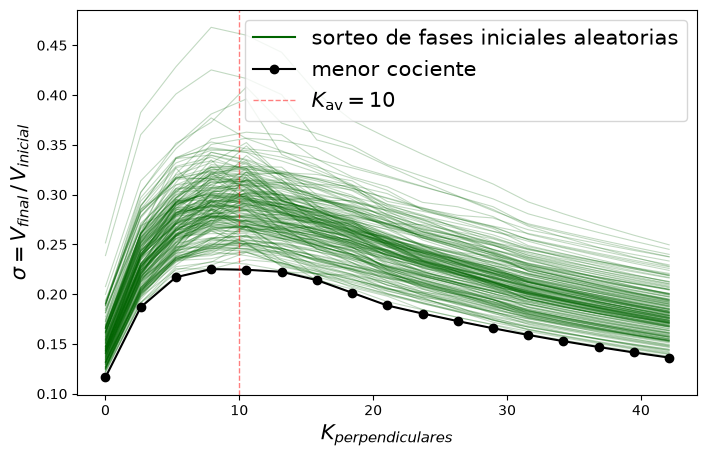

In [5]:
from scipy.sparse import csr_matrix, identity, kron

BARRIDO = True    # False para saltear el barrido

if BARRIDO:
    N_K    = 20      # cuántos valores de K_perpendiculares
    N_CI   = 200      # condiciones iniciales por cada valor
    T_MAX  = 300     # tiempo máximo por simulación
    TOL    = 1e-6    # se considera convergido cuando max|dphi/dt| < TOL
    K_AV   = 10      # peso de avenidas y calles paralelas
    KP_MIN = 0.0     # primer K_perp del barrido (si falla en 0, poné 0.1)
    KP_MAX = 5*K_AV  # último K_perp del barrido
    DESCARTAR = 3    # cuántos de los últimos K no se grafican (0 = graficar todos)

    m = 10
    n = 3 * m
    A = matriz_ady1(m)
    Delta = np.full((n, n), 2 * np.pi / 8)
    d = A[0].sum()

    # las N_CI condiciones iniciales de un mismo K se integran juntas: una fila por sorteo (semilla b)
    PHI0 = np.array([condiciones_iniciales_random(n, semilla=b) for b in range(N_CI)])      # (N_CI, n)

    # cada sorteo solo depende de sí mismo: el jacobiano es por bloques (y de la forma de A), lo que acelera el integrador
    patron = kron(identity(N_CI), csr_matrix(A + np.eye(n)), format="csr")

    def pesos_trig(K):
        # las mismas ecuaciones, reescritas con senos y cosenos de cada fase para usar solo productos de matrices
        W1 = A * (0.5*K.T*np.cos(Delta.T) + 0.5*K*np.cos(Delta))
        W2 = A * (-0.5*K.T*np.sin(Delta.T) + 0.5*K*np.sin(Delta))
        return W1.T, W2.T

    def rhs_lote(t, y, W1T, W2T):
        s, c = np.sin(y.reshape(N_CI, n)), np.cos(y.reshape(N_CI, n))
        return ((c*(s @ W1T + c @ W2T) + s*(s @ W2T - c @ W1T)) / d).ravel()

    def convergio(t, y, W1T, W2T):                               # corta cuando todos los./osu*.AppImage sorteos llegaron a un mínimo
        return np.abs(rhs_lote(t, y, W1T, W2T)).max() - TOL
    convergio.terminal = True

    def V_lote(phi, K):                                          # V de cada sorteo (fila de phi)
        D = phi[:, None, :] - phi[:, :, None]                    # D[b,i,j] = phi_j - phi_i
        return ((A*0.5*K.T) * (1 - np.cos(D - Delta.T))).sum(axis=(1, 2)) / d

    # --- barrido ---
    kps = np.linspace(KP_MIN, KP_MAX, N_K)
    Vfin = np.zeros((N_K, N_CI))
    V0 = np.zeros((N_K, N_CI))
    sin_converger = 0

    for a, kp in enumerate(kps):
        K = matriz_K1(m, K_AV, kp)
        W1T, W2T = pesos_trig(K)
        sol = solve_ivp(rhs_lote, (0, T_MAX), PHI0.ravel(), method="BDF", args=(W1T, W2T),
                        events=convergio, jac_sparsity=patron, rtol=1e-6, atol=1e-8)
        phi_fin = sol.y[:, -1].reshape(N_CI, n)
        Vfin[a] = V_lote(phi_fin, K)
        V0[a] = V_lote(PHI0, K)
        if sol.status != 1:                                      # no se llegó al mínimo en T_MAX
            sin_converger += (np.abs(rhs_lote(0, sol.y[:, -1], W1T, W2T).reshape(N_CI, n)).max(axis=1) > TOL).sum()

    print("simulaciones que no llegaron a un mínimo en T_MAX:", sin_converger)

    # --- gráfico: V final / V inicial, sin los últimos K ---
    sl = slice(0, N_K - DESCARTAR)
    cociente = Vfin / V0


plt.figure(figsize=(8, 5))
plt.plot(kps[sl], cociente[sl], color="darkgreen", lw=0.8,  alpha = 0.24)
plt.plot([], [], color="darkgreen", label="sorteo de fases iniciales aleatorias")
plt.plot(kps[sl], cociente[sl].min(axis=1), "o-", color="black", label="menor cociente")
plt.axvline(10, color="red", linestyle="--", linewidth=1, alpha=0.5, label= r"$K_\text{av} = 10$")
plt.xlabel(r"$K_{perpendiculares}$", fontsize = 15)
plt.ylabel(r"$\sigma = V_{final}\,/\,V_{inicial}$", fontsize = 15)
plt.legend(fontsize = 15)
plt.show()